# 03 · Preserve the working collaborative component
Neighbor-smoothed category histories from real NetEase interactions.

In [1]:
from pathlib import Path
import sys, json, inspect
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks': ROOT=ROOT.parent
if str(ROOT.parent) not in sys.path: sys.path.insert(0,str(ROOT.parent))
from ml.src.preprocessing import load_data, read_json, save_json
from ml.src.evaluation import evaluate, feature_groups
from ml.src.notebook_helpers import table, metric_row, chart
from IPython.display import display, Code
import matplotlib.pyplot as plt
%matplotlib inline


For worker u and category c, CF=(training successes + 4×neighbor prior)/(training count+4). The prior averages other workers’ smoothed category success `(s+2)/(n+4)` using profile Jaccard similarity. In the preserved model the neutral capability catalog makes these similarities equal. This is history-based smoothing, not matrix factorization. The new content component uses separate empirical capability profiles; it does not silently alter this baseline.

def components(self, a, t):
        h = self.history.get(a['id'], {}).get(t['category'], [0, 0])
        weighted = total = 0
        # Training-profile neighbors remain fixed even when current availability changes.
        for b in self.agents:
            if b['id'] == a['id']: continue
            bh = self.history.get(b['id'], {}).get(t['category'], [0, 0])
            union = set(a['skills']) | set(b['skills'])
            similarity = len(set(a['skills']) & set(b['skills'])) / max(1, len(union))
            if bh[1] and similarity:
                weighted += similarity * (bh[0] + 2) / (bh[1] + 4)
                total += similarity
        prior = weighted / total if total else .5
        return [
            .65 * (t['skill'] in a['skills']) + .35 * (a['location'] == t['location']),
            (h[0] + 4 * prior) / (h[1] + 4),
            .55 * a['quality'] + .45 * (1 - a['workload'] / a['capacity']),
        ]

Source worker,"Capability histories [successes, count]"
57,"{'NetEase capability 53': [1043, 1109]}"
59,"{'NetEase capability 53': [820, 864]}"
61,"{'NetEase capability 53': [756, 820]}"
105,"{'NetEase capability 53': [740, 789]}"
282,"{'NetEase capability 53': [400, 449]}"


Model,Top-1 %,P@3 %,R@3 %,MAP@3 %,Full MAP %,NDCG@3 %
Collaborative / validation,83.152,81.648,65.561,77.029,85.895,82.128


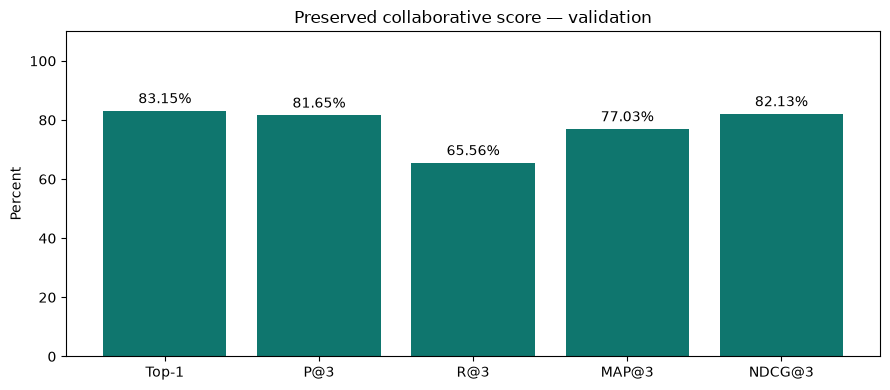

In [2]:
from ml.salesmesh_ml.engine import HybridRecommender
model=HybridRecommender.load(ROOT/'models/netease/legacy_model.json')
display(Code(inspect.getsource(model.components),language='python'))
table([{'Source worker':w,'Capability histories [successes, count]':history} for w,history in list(model.history.items())[:5]])
groups,splits=load_data(); features=read_json('models/netease/features.json')
result=evaluate(feature_groups(groups,splits['validation'],features),(0,1,0),3)
table([metric_row('Collaborative / validation',result)])
chart('Preserved collaborative score — validation',result,'collaborative.png')